In [95]:
import pandas as pd
import numpy as np

In [96]:
df_wine = pd.read_csv("./dataset/02_wine_noisy_exe.csv")
df_wine.info() # sugar 컬럼 및 ph 컬럼 결측치 확인
cols = ["alcohol", "sugar", "pH", "class"]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6497 non-null   float64
 1   sugar    6496 non-null   float64
 2   pH       6496 non-null   float64
 3   class    6497 non-null   int64  
dtypes: float64(3), int64(1)
memory usage: 203.2 KB


In [97]:
df_wine.describe()
# 확실한 것 : alcohol 이상치 확인

,alcohol,sugar,pH,class
count,6497.000000,6496.000000,6496.000000,6497.000000
mean,12.029357,5.443796,3.218458,0.753886
std,123.938942,4.757955,0.160762,0.430779
min,8.000000,0.600000,2.720000,0.000000
25%,9.500000,1.800000,3.110000,1.000000
50%,10.300000,3.000000,3.210000,1.000000
75%,11.300000,8.100000,3.320000,1.000000
max,10000.000000,65.800000,4.010000,1.000000


In [98]:
df_wine.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6497 non-null   float64
 1   sugar    6496 non-null   float64
 2   pH       6496 non-null   float64
 3   class    6497 non-null   int64  
dtypes: float64(3), int64(1)
memory usage: 203.2 KB


In [99]:
# 결측치 수 확인
for col in cols:
    print(f"{col}의 결측치 수", df_wine[col].isna().sum())

alcohol의 결측치 수 0
sugar의 결측치 수 1
pH의 결측치 수 1
class의 결측치 수 0


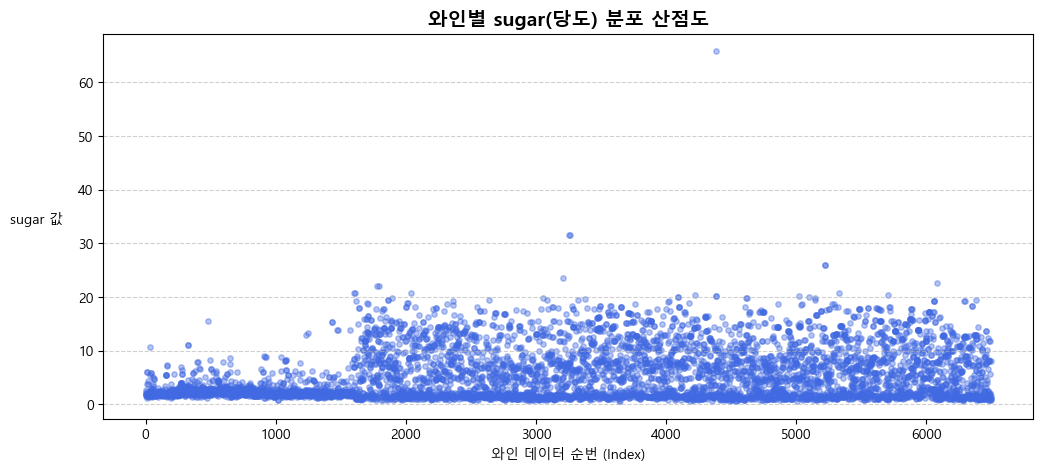

In [100]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(12, 5))

# x축에 데이터 순번(df_wine.index), y축에 sugar 컬럼 값
# alpha=0.4를 주면 점들이 겹쳐서 진해지므로 대부분의 데이터가 어디 밀집되어 있는지 잘 보입니다.
plt.scatter(x=df_wine.index, y=df_wine['sugar'], alpha=0.4, color='royalblue', s=15)

plt.title('와인별 sugar(당도) 분포 산점도', fontsize=14, fontweight='bold')
plt.xlabel('와인 데이터 순번 (Index)')
plt.ylabel('sugar 값', rotation=0, labelpad=30)
plt.grid(axis='y', linestyle='--', alpha=0.6)  # 눈금을 보기 편하게 보조선 추가

plt.show()

In [101]:
# 복사본 만들고 sugar 컬럼 결측치 삭제 후 이상치 측정
df_wine_c = df_wine.copy()
df_wine_c = df_wine_c.dropna(subset=['sugar'])
df_wine_c.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6496 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6496 non-null   float64
 1   sugar    6496 non-null   float64
 2   pH       6495 non-null   float64
 3   class    6496 non-null   int64  
dtypes: float64(3), int64(1)
memory usage: 253.8 KB


In [102]:
# sugar 이상치 먼저 제거하기
z_score_c = np.abs((df_wine_c["sugar"] - df_wine_c["sugar"].mean()) / df_wine_c["sugar"].std())

In [103]:
df_wine_c = df_wine_c[z_score_c < 3]
df_wine_c.info()
df_wine_c.describe()
df_wine.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6470 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6470 non-null   float64
 1   sugar    6470 non-null   float64
 2   pH       6469 non-null   float64
 3   class    6470 non-null   int64  
dtypes: float64(3), int64(1)
memory usage: 252.7 KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6497 non-null   float64
 1   sugar    6496 non-null   float64
 2   pH       6496 non-null   float64
 3   class    6497 non-null   int64  
dtypes: float64(3), int64(1)
memory usage: 203.2 KB


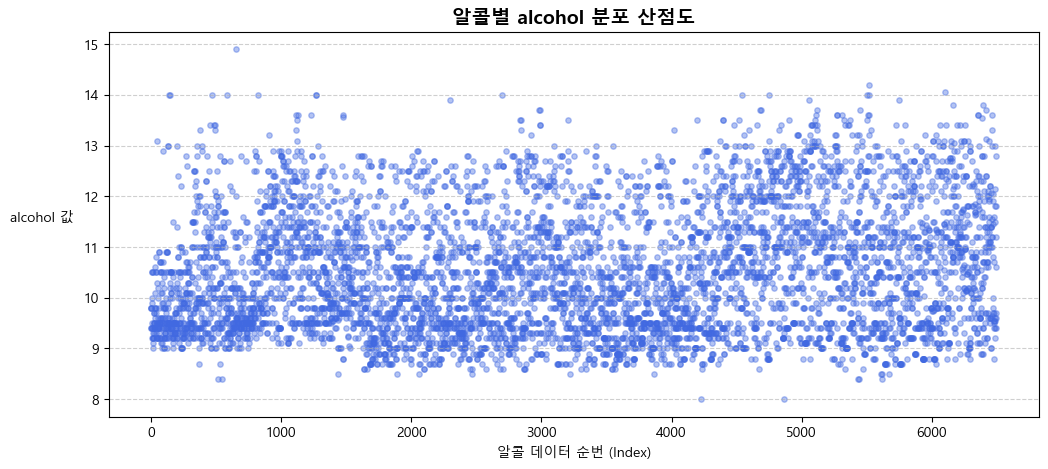

In [104]:
df_wine_c = df_wine_c[df_wine_c["alcohol"] != 10000]
plt.figure(figsize=(12, 5))

# x축에 데이터 순번(df_wine.index), y축에 sugar 컬럼 값
# alpha=0.4를 주면 점들이 겹쳐서 진해지므로 대부분의 데이터가 어디 밀집되어 있는지 잘 보입니다.
plt.scatter(x=df_wine_c.index, y=df_wine_c['alcohol'], alpha=0.4, color='royalblue', s=15)

plt.title('알콜별 alcohol 분포 산점도', fontsize=14, fontweight='bold')
plt.xlabel('알콜 데이터 순번 (Index)')
plt.ylabel('alcohol 값', rotation=0, labelpad=30)
plt.grid(axis='y', linestyle='--', alpha=0.6)  # 눈금을 보기 편하게 보조선 추가

plt.show()

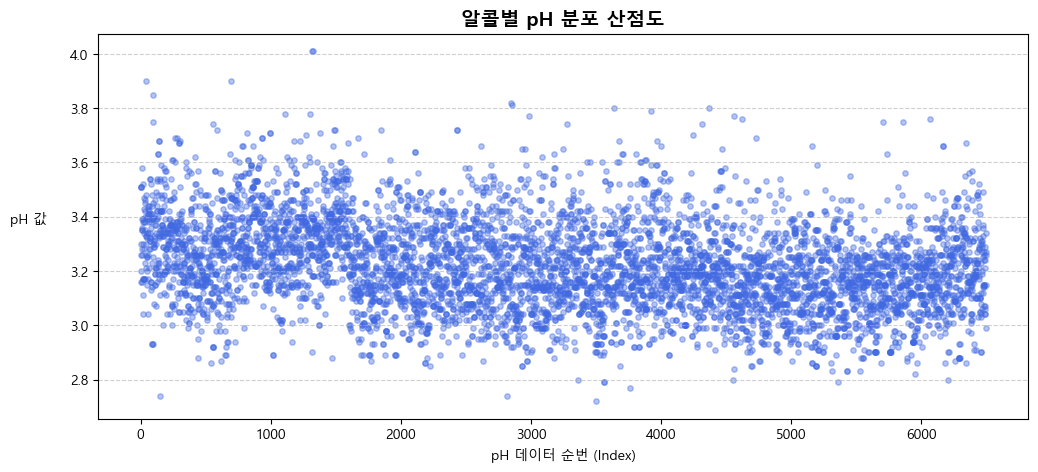

In [105]:

plt.figure(figsize=(12, 5))

# x축에 데이터 순번(df_wine.index), y축에 sugar 컬럼 값
# alpha=0.4를 주면 점들이 겹쳐서 진해지므로 대부분의 데이터가 어디 밀집되어 있는지 잘 보입니다.
plt.scatter(x=df_wine.index, y=df_wine['pH'], alpha=0.4, color='royalblue', s=15)

plt.title('알콜별 pH 분포 산점도', fontsize=14, fontweight='bold')
plt.xlabel('pH 데이터 순번 (Index)')
plt.ylabel('pH 값', rotation=0, labelpad=30)
plt.grid(axis='y', linestyle='--', alpha=0.6)  # 눈금을 보기 편하게 보조선 추가

plt.show()

In [106]:
# 결측치 채우기
def fillna(df_wine1):
    df_wine1["sugar"] = df_wine1["sugar"].fillna(df_wine_c["sugar"].median())
    df_wine1["pH"] = df_wine1["pH"].fillna(df_wine1["pH"].mean())

    return df_wine1
fillna(df_wine)
df_wine.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6497 non-null   float64
 1   sugar    6497 non-null   float64
 2   pH       6497 non-null   float64
 3   class    6497 non-null   int64  
dtypes: float64(3), int64(1)
memory usage: 203.2 KB


In [107]:
z_score_s = np.abs((df_wine["sugar"] - df_wine["sugar"].mean()) / df_wine["sugar"].std())
z_score_a = np.abs((df_wine["alcohol"] - df_wine["alcohol"].mean()) / df_wine["alcohol"].std())

In [108]:
df_wine= df_wine[(z_score_s < 3) & (z_score_a < 3)]
df_wine.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6470 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6470 non-null   float64
 1   sugar    6470 non-null   float64
 2   pH       6470 non-null   float64
 3   class    6470 non-null   int64  
dtypes: float64(3), int64(1)
memory usage: 252.7 KB


In [109]:
df_wine.reset_index(inplace=True, drop=True)

In [110]:
df_wine["sugar"] = df_wine["sugar"].round().astype("int")
df_wine.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6470 entries, 0 to 6469
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6470 non-null   float64
 1   sugar    6470 non-null   int64  
 2   pH       6470 non-null   float64
 3   class    6470 non-null   int64  
dtypes: float64(2), int64(2)
memory usage: 202.3 KB


In [111]:
### 사용할 라이브러리 불러들이기

# 데이터 조작을 위한 라이브러리
import pandas as pd

# 기본 시각화 라이브러리
import matplotlib.pyplot as plt

# 통계적 시각화 라이브러리(보통 기본 시각화보다 향상된 라이브러리라고 생각하면 됨)
import seaborn as sns

# 시각화 시 그래프의 너비/높이 기본 설정하기(단위=인치)
plt.rcParams["figure.figsize"] = (12, 5)

# 시각화시 한글 깨짐 처리를 위한 폰트 지정(Window OS 기준, Mac OS나 Linux는 그에 맞게)
plt.rcParams['font.family'] = 'Malgun Gothic'

# 시각화시 마이너스(-) 기호 깨짐 방지 처리
plt.rcParams['axes.unicode_minus'] = False

### 유의미성(p-value)을 확인하기 위한 라이브러리(통계 라이브러리라고도 칭함)
# - 유의미성 확인 방법 : 피어슨 및 스피어만 방식을 사용
from scipy import stats

In [112]:
corr_matrix = df_wine.corr(method="pearson")
corr_matrix

# if값 써서 절댓값이 0.1보다 크거나 같다면 사용하려고 함.

,alcohol,sugar,pH,class
alcohol,1.000000,-0.366466,0.119060,0.034445
sugar,-0.366466,1.000000,-0.267906,0.353365
pH,0.119060,-0.267906,1.000000,-0.327957
class,0.034445,0.353365,-0.327957,1.000000


<function matplotlib.pyplot.show(close=None, block=None)>

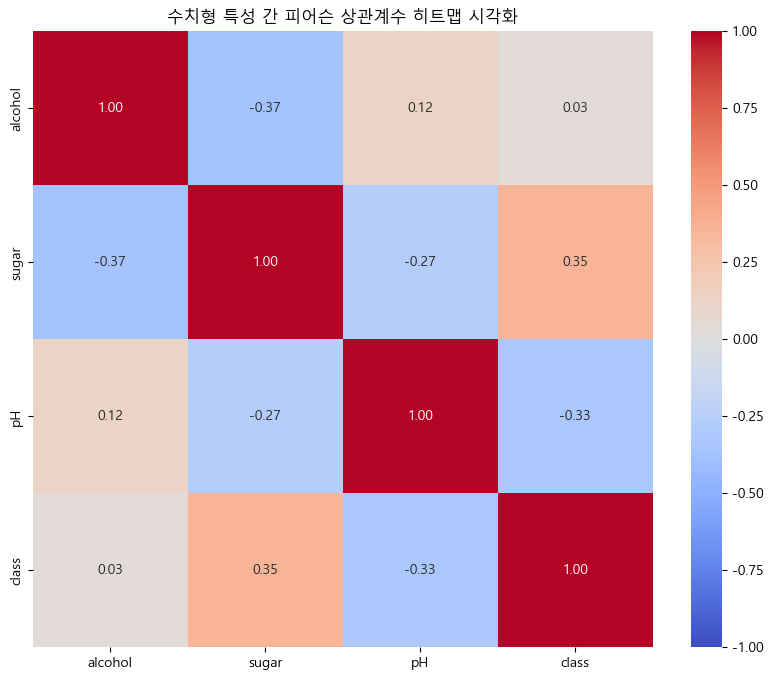

In [113]:
plt.figure(figsize=(10,8))

### 히트맵 그래프 그리기
#  - annot=True: 박스 안에 수치 표시,
#  - fmt='.2f': 소수점 둘째 자리까지 표시,
#  - cmap='coolwarm': 한랭/온난 색상 맵 적용
#  - vmin/vmax : 히트맵의 색상 막대(Colorbar)가 표현할 최소값과 최대값을 고정하는 값
plt.title('수치형 특성 간 피어슨 상관계수 히트맵 시각화')
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)

plt.show

In [119]:
cols2 = ["alcohol", "sugar", "pH"]

for col2 in cols2:
    spearman_coef, p_values_pearman = stats.spearmanr(df_wine["class"], df_wine[col2]) #항상 두개씩 넣기
    
    if p_values_pearman < 0.05:
        print(f"class vs {col2} = {spearman_coef: .3f} / p-value = {p_values_pearman: .10f}")
        print("{col2}과 class 간의 관계는 유의미 합니다")
    elif p_values_pearman >= 0.05:
        False

class vs sugar =  0.295 / p-value =  0.0000000000
{col2}과 class 간의 관계는 유의미 합니다
class vs pH = -0.335 / p-value =  0.0000000000
{col2}과 class 간의 관계는 유의미 합니다


In [ ]:
# 알콜(%), 당류(g), 산도(pH) 단위가 달라서 스케일링해주는 것임. 범위가 다르니.

In [121]:
class_counts = df_wine["class"].value_counts()
class_counts

class
1    4872
0    1598
Name: count, dtype: int64